# Modèle de retard de livraison
Baseline vs 2 algorithmes, validation croisée, métriques adaptées au déséquilibre, importance des variables et audit d'équité.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
from shoppulse.features.engineering import build_delay_features, TARGET
from shoppulse.models import delay, equity

In [2]:
df = build_delay_features()
print(len(df), 'commandes | taux de retard =', round(df[TARGET].mean(), 3))
df.head()

96470 commandes | taux de retard = 0.081


,distance_km,delai_estime_jours,poids_total,volume_moy,fret_total,prix_total,n_items,seller_order_count,customer_state,seller_state,en_retard
0,13.559770,11.0,400.0,2816.0,15.56,90.0,2,17,SP,SP,0
1,4.560727,15.0,400.0,2816.0,15.56,70.0,2,17,SP,SP,0
2,16.185443,14.0,100.0,8000.0,7.78,35.0,1,17,SP,SP,0
3,30.663562,11.0,100.0,8000.0,7.39,35.0,1,17,SP,SP,0
4,318.221851,10.0,200.0,2816.0,12.98,45.0,1,17,SP,SP,1


## Validation croisée (baseline + logreg + random forest)

In [3]:
cv = delay.cross_validate_models(df)
cv

,modele,roc_auc,average_precision,f1,recall,precision
0,baseline,0.5009,0.0813,0.0830,0.0832,0.0828
1,logreg,0.6939,0.1641,0.2252,0.6274,0.1372
2,random_forest,0.7190,0.1917,0.2539,0.5659,0.1637


## Modèle retenu, importance des variables

In [4]:
pipe, metrics, test_df = delay.train_best(df, 'random_forest')
print('ROC-AUC', metrics['roc_auc'], '| PR-AUC', metrics['pr_auc'])
imp = delay.feature_importances(pipe); imp

ROC-AUC 0.717 | PR-AUC 0.1993


,feature,importance
0,num__delai_estime_jours,0.303919
1,num__distance_km,0.134089
2,num__fret_total,0.070148
3,cat__customer_state_RJ,0.067364
4,num__seller_order_count,0.057829
5,cat__customer_state_SP,0.056959
6,num__volume_moy,0.054458
7,num__prix_total,0.054060
8,num__poids_total,0.048969
9,cat__seller_state_SP,0.023947


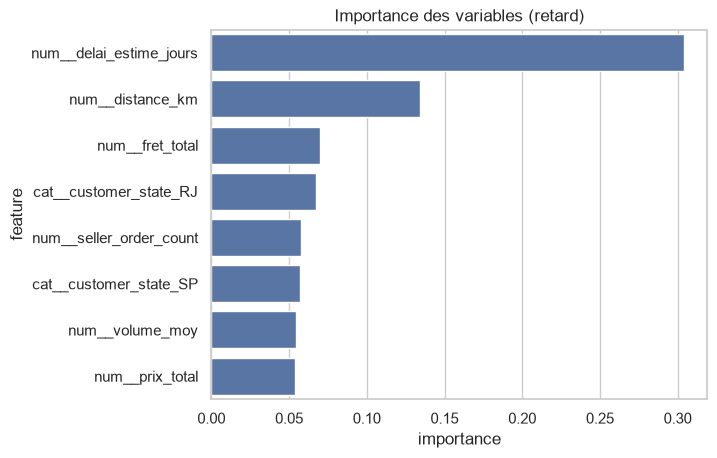

In [5]:
ax = sns.barplot(x='importance', y='feature', data=imp.head(8))
ax.set_title('Importance des variables (retard)'); plt.show()

## Audit d'équité par région

In [6]:
audit = equity.audit_by_region(pipe, test_df)
print(equity.equity_gap(audit))
audit.head(10)

{'ecart_rappel': np.float64(0.8626), 'ecart_fpr': np.float64(0.6774)}


,region,effectif,taux_retard_reel,taux_retard_prevu,rappel,taux_faux_positifs
0,MA,154,0.2078,0.7468,0.9375,0.6967
1,CE,239,0.1548,0.6695,0.8108,0.6436
2,BA,657,0.1385,0.6621,0.7912,0.6413
3,PE,338,0.1361,0.5266,0.6087,0.5137
4,MS,152,0.1316,0.6316,0.8500,0.5985
5,RJ,2496,0.1310,0.7095,0.9083,0.6796
6,RN,101,0.1287,0.6139,0.6923,0.6023
7,PA,199,0.1005,0.3568,0.5000,0.3408
8,ES,391,0.0946,0.6317,0.9459,0.5989
9,RS,1006,0.0875,0.1372,0.3295,0.1187


## Interprétation
La distance client-vendeur et le délai estimé dominent. La Random Forest classe le mieux (ROC-AUC), mais le rappel au seuil 0,5 est faible : en production, abaisser le seuil pour anticiper davantage de retards. L'audit d'équité révèle des écarts régionaux à surveiller (cf. note éthique).